# 3804ICT ASSIGNMENT 1: DATA MINING PROJECT PROPOSAL
## Predicting Bank Telemarketing Success Using KNN & Decision Tree
### _Griffith University, Trimester 2, 2026_

#### _Chanh Pham (S5052032) & Farah Hannah Abdurahman (S5353326)_


In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("bank-additional-full.csv", delimiter=";")
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


#### 7. Apply Data Pre-processing for KNN and Decision Tree

_The following cells apply the proposed treatments and create a common train/test split for both classifiers. The same cleaned observations and target labels are used for both models. Model-specific transformations are applied only after the split to avoid data leakage._


##### 7.1 Create a modelling copy and remove exact duplicate rows

_The original `df` is preserved for exploration. Exact duplicate rows are removed from a separate modelling copy before the train/test split so that identical rows cannot appear in both sets._


In [3]:
# Preserve the original dataframe used for exploration
model_df = df.copy()

rows_before = len(model_df)
duplicates_before = model_df.duplicated().sum()

model_df = model_df.drop_duplicates().reset_index(drop=True)

print("Rows before duplicate removal:", rows_before)
print("Exact duplicates removed:", duplicates_before)
print("Rows after duplicate removal:", len(model_df))


Rows before duplicate removal: 41188
Exact duplicates removed: 12
Rows after duplicate removal: 41176


##### 7.2 Treat the `pdays = 999` sentinel value

_According to the dataset definition, `999` indicates that a client was not previously contacted. It is therefore separated into (1) a binary previous-contact indicator and (2) the number of days since contact. For clients who were never contacted, `pdays_since_contact` is set to 0 and is interpreted together with `previously_contacted = 0`. The original `pdays` column is then removed._


In [4]:
# Preserve the semantic meaning of pdays = 999
model_df["previously_contacted"] = (model_df["pdays"] != 999).astype(int) #1 for yes, 0 for no
model_df["pdays_since_contact"] = model_df["pdays"].where(model_df["pdays"] != 999, 0)

# The original sentinel-coded column is no longer required
model_df = model_df.drop(columns=["pdays"])

model_df[["previously_contacted", "pdays_since_contact"]].tail(10)

,previously_contacted,pdays_since_contact
41166,1,6
41167,0,0
41168,0,0
41169,0,0
41170,1,9
41171,0,0
41172,0,0
41173,0,0
41174,0,0
41175,0,0


##### 7.3 Retain valid zero values and potential outliers

_`previous = 0` is retained because it is a valid value meaning that no contacts occurred before the current campaign. IQR-identified extreme values are also retained because the exploration did not establish that they are erroneous. The categorical value `"unknown"` is kept as a legitimate separate category and will be encoded rather than deleted._


In [5]:
# No row deletion is performed for IQR-identified potential outliers.
# "unknown" categorical values are also intentionally retained.

print("previous = 0 records:", (model_df["previous"] == 0).sum())

unknown_remaining = { col: int((model_df[col] == "unknown").sum()) 
                      for col in model_df.select_dtypes(exclude=np.number).columns if (model_df[col] == "unknown").any()
}

print("Unknown categorical values retained:")
print(unknown_remaining)


previous = 0 records: 35551
Unknown categorical values retained:
{'job': 330, 'marital': 80, 'education': 1730, 'default': 8596, 'housing': 990, 'loan': 990}


##### 7.4 Remove `duration` for a realistic future-campaign prediction

_The stated project aim is to help target future marketing campaigns. The complete call duration is only known after a call has finished, so using it for a pre-contact prediction would introduce information that is unavailable at prediction time. It is therefore removed from the modelling dataset. If the project is later redefined as a post-call classification task, this decision can be reconsidered._


In [6]:
# Remove a prediction-time leakage feature for the future-targeting scenario
if "duration" in model_df.columns:
    model_df = model_df.drop(columns=["duration"])

print("Attributes available before separating the target:", model_df.shape[1] - 1)


Attributes available before separating the target: 20


##### 7.5 Separate predictors and target, then perform one shared stratified split

_The binary target is encoded as `no = 0` and `yes = 1`. Stratification preserves approximately the same class proportions in the training and testing sets. Splitting is performed before fitting encoders or scalers so that the test set does not influence preprocessing._


In [7]:
from sklearn.model_selection import train_test_split

X = model_df.drop(columns=["y"])
y = model_df["y"].map({"no": 0, "yes": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print()
print("Training target distribution (%):")
print((y_train.value_counts(normalize=True).sort_index() * 100).round(2))
print()
print("Testing target distribution (%):")
print((y_test.value_counts(normalize=True).sort_index() * 100).round(2))


Training samples: 32940
Testing samples: 8236

Training target distribution (%):
y
0    88.73
1    11.27
Name: proportion, dtype: float64

Testing target distribution (%):
y
0    88.73
1    11.27
Name: proportion, dtype: float64


##### 7.6 Identify numerical and categorical predictors after feature engineering

_These lists are derived from the training data and are shared by both model pipelines._


In [14]:
numerical_features = X_train.select_dtypes(include=["number"]).columns.tolist()

categorical_features = X_train.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Numerical predictors:", numerical_features)
print()
print("Categorical predictors:", categorical_features)

Numerical predictors: ['age', 'campaign', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'previously_contacted', 'pdays_since_contact']

Categorical predictors: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


##### 7.7 KNN preprocessing: one-hot encoding + numerical scaling

_KNN is distance-based. Categorical predictors are one-hot encoded, while numerical predictors are standardised so that attributes with larger numerical ranges do not dominate the distance calculation. The encoder and scaler are fitted only on the training set._


In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

knn_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_features)
    ],
    verbose_feature_names_out=False
)

X_train_knn = knn_preprocessor.fit_transform(X_train)
X_test_knn = knn_preprocessor.transform(X_test)

knn_feature_names = knn_preprocessor.get_feature_names_out()

print("KNN training matrix:", X_train_knn.shape)
print("KNN testing matrix:", X_test_knn.shape)
print("KNN contains NaN:", np.isnan(X_train_knn).any() or np.isnan(X_test_knn).any())


KNN training matrix: (32940, 63)
KNN testing matrix: (8236, 63)
KNN contains NaN: False


In [15]:
print("KNN feature count after encoding:", X_train_knn.shape[1])
print("Original exact duplicate rows removed:", duplicates_before)
print("Remaining null values in modelling data:", model_df.isnull().sum().sum())


KNN feature count after encoding: 63
Original exact duplicate rows removed: 12
Remaining null values in modelling data: 0


In [16]:
#Convert Labels to numpy arrays
import numpy as np

y_train_knn = np.asarray(y_train, dtype=int)
y_test_knn = np.asarray(y_test, dtype=int)

#Convert Features to numpy arrays
X_train_knn = np.asarray(X_train_knn, dtype=float)
X_test_knn = np.asarray(X_test_knn, dtype=float)

#Verify
print("X_train_knn:", X_train_knn.shape)
print("X_test_knn :", X_test_knn.shape)
print("y_train_knn:", y_train_knn.shape)
print("y_test_knn :", y_test_knn.shape)

print("\nTraining dtype:", X_train_knn.dtype)
print("Testing dtype :", X_test_knn.dtype)

print("\nNaNs in training:", np.isnan(X_train_knn).sum())
print("NaNs in testing :", np.isnan(X_test_knn).sum())

print("\nTraining classes:")
print(np.unique(y_train_knn, return_counts=True))

print("\nTesting classes:")
print(np.unique(y_test_knn, return_counts=True))

X_train_knn: (32940, 63)
X_test_knn : (8236, 63)
y_train_knn: (32940,)
y_test_knn : (8236,)

Training dtype: float64
Testing dtype : float64

NaNs in training: 0
NaNs in testing : 0

Training classes:
(array([0, 1]), array([29229,  3711]))

Testing classes:
(array([0, 1]), array([7308,  928]))


In [17]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

majority_prediction = np.zeros_like(y_test_knn)

baseline_accuracy = accuracy_score(y_test_knn, majority_prediction)
baseline_precision = precision_score(
    y_test_knn,
    majority_prediction,
    zero_division=0
)
baseline_recall = recall_score(
    y_test_knn,
    majority_prediction,
    zero_division=0
)
baseline_f1 = f1_score(
    y_test_knn,
    majority_prediction,
    zero_division=0
)

print("Majority-class baseline")
print(f"Accuracy : {baseline_accuracy:.4f}")
print(f"Precision: {baseline_precision:.4f}")
print(f"Recall   : {baseline_recall:.4f}")
print(f"F1-score : {baseline_f1:.4f}")

Majority-class baseline
Accuracy : 0.8873
Precision: 0.0000
Recall   : 0.0000
F1-score : 0.0000


## Custom KNN Implementation

In [18]:
import numpy as np


class CustomKNN:
    def __init__(self, k=5):
        if not isinstance(k, int) or k <= 0:
            raise ValueError("k must be a positive integer.")

        self.k = k
        self.X_train = None
        self.y_train = None


    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=int)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if y.ndim != 1:
            raise ValueError("y must be a 1D array.")

        if len(X) != len(y):
            raise ValueError("X and y must contain the same number of samples.")

        if self.k > len(X):
            raise ValueError("k cannot be larger than the number of training samples.")

        self.X_train = X
        self.y_train = y

        return self


    @staticmethod
    def _euclidean_distance(x1, x2):
        x1 = np.asarray(x1, dtype=float)
        x2 = np.asarray(x2, dtype=float)

        if x1.shape != x2.shape:
            raise ValueError("Both observations must have the same number of features.")

        return np.sqrt(np.sum((x1 - x2) ** 2))


    def _get_neighbors(self, x):
        distances = np.sqrt(np.sum((self.X_train - x) ** 2, axis=1))

        neighbor_indices = np.argpartition(distances, self.k - 1)[:self.k]

        neighbor_indices = neighbor_indices[np.argsort(distances[neighbor_indices])]

        neighbor_labels = self.y_train[neighbor_indices]
        neighbor_distances = distances[neighbor_indices]

        return neighbor_labels, neighbor_distances


    @staticmethod
    def _majority_vote(labels, distances):
        classes, counts = np.unique(labels, return_counts=True)

        max_count = np.max(counts)
        winning_classes = classes[counts == max_count]

        if len(winning_classes) == 1:
            return winning_classes[0]

        for label in labels:
            if label in winning_classes:
                return label


    def _predict_one(self, x):
        labels, distances = self._get_neighbors(x)

        return self._majority_vote(labels, distances)


    def predict(self, X):
        if self.X_train is None or self.y_train is None:
            raise RuntimeError("The model must be fitted before prediction.")

        X = np.asarray(X, dtype=float)

        if X.ndim != 2:
            raise ValueError("X must be a 2D array.")

        if X.shape[1] != self.X_train.shape[1]:
            raise ValueError("Prediction data must have the same number of features as training data.")

        predictions = np.array([self._predict_one(x) for x in X])

        return predictions

In [19]:
#Full Class Test
X_small = np.array([
    [1, 1],
    [1, 2],
    [4, 4],
    [5, 4]
])

y_small = np.array([
    0,
    0,
    1,
    1
])

In [20]:
knn_test = CustomKNN(k=3)

knn_test.fit(
    X_small,
    y_small
)

In [21]:
print(
    knn_test._euclidean_distance(
        np.array([1, 1]),
        np.array([4, 5])
    )
)

5.0


In [22]:
#Predict
test_points = np.array([
    [1, 1.5],
    [4.5, 4]
])

predictions = knn_test.predict(test_points)

print(predictions)

[0 1]


In [23]:
#Test fit() on actual data
custom_knn = CustomKNN(k=5)

custom_knn.fit(
    X_train_knn,
    y_train_knn
)

In [24]:
print(custom_knn.k)
print(custom_knn.X_train.shape)
print(custom_knn.y_train.shape)

5
(32940, 63)
(32940,)


In [25]:
#small 5 test
sample_predictions = custom_knn.predict(
    X_test_knn[:5]
)

print("Predictions:", sample_predictions)
print("Actual     :", y_test_knn[:5])

Predictions: [0 1 0 0 0]
Actual     : [0 1 0 0 0]


In [27]:
#Scikit-learn comparison
from sklearn.neighbors import KNeighborsClassifier

sklearn_test = KNeighborsClassifier(
    n_neighbors=5,
    metric="euclidean",
    weights="uniform",
    algorithm="brute"
)

sklearn_test.fit(
    X_train_knn,
    y_train_knn
)

sklearn_predictions = sklearn_test.predict(
    X_test_knn[:5]
)

print("Custom :", sample_predictions)
print("sklearn:", sklearn_predictions)

Custom : [0 1 0 0 0]
sklearn: [0 1 0 0 0]


In [28]:
#Selecting K using training data
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
import numpy as np

candidate_k = [3, 5, 7, 9, 11, 13, 15] #odd-value to reduce voting ties

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

mean_f1_scores = []

for k in candidate_k:
    model = KNeighborsClassifier(
        n_neighbors=k,
        metric="euclidean",
        weights="uniform",
        algorithm="brute"
    )

    scores = cross_val_score(
        model,
        X_train_knn,
        y_train_knn,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    mean_f1_scores.append(scores.mean())

    print(
        f"k={k:2d} | "
        f"Mean F1={scores.mean():.4f} | "
        f"Std={scores.std():.4f}"
    )


k= 3 | Mean F1=0.3650 | Std=0.0170
k= 5 | Mean F1=0.3800 | Std=0.0108
k= 7 | Mean F1=0.3813 | Std=0.0057
k= 9 | Mean F1=0.3734 | Std=0.0082
k=11 | Mean F1=0.3642 | Std=0.0119
k=13 | Mean F1=0.3664 | Std=0.0125
k=15 | Mean F1=0.3594 | Std=0.0158


In [29]:
best_index = np.argmax(mean_f1_scores)

best_k = candidate_k[best_index]
best_f1 = mean_f1_scores[best_index]

print("\nBest k:", best_k)
print("Best cross-validation F1:", round(best_f1, 4))


Best k: 7
Best cross-validation F1: 0.3813


In [30]:
BEST_K = best_k

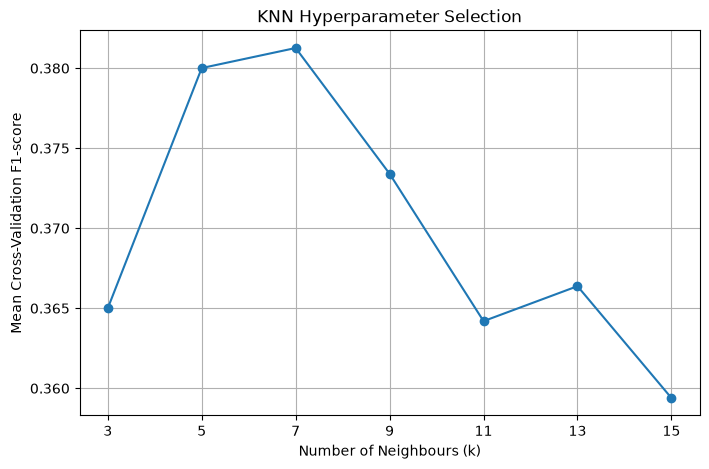

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(
    candidate_k,
    mean_f1_scores,
    marker="o"
)

plt.xlabel("Number of Neighbours (k)")
plt.ylabel("Mean Cross-Validation F1-score")
plt.title("KNN Hyperparameter Selection")
plt.xticks(candidate_k)
plt.grid(True)
plt.show()

### KNN Preparation

In [32]:
custom_knn = CustomKNN(
    k=BEST_K
)

custom_knn.fit(
    X_train_knn,
    y_train_knn
)

In [33]:
sklearn_knn = KNeighborsClassifier(
    n_neighbors=BEST_K,
    metric="euclidean",
    weights="uniform",
    algorithm="brute"
)

sklearn_knn.fit(X_train_knn, y_train_knn)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",7
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'brute'
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'euclidean'
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [35]:
# K value check prior to testing
print("Selected k:", BEST_K)

print(
    "Custom KNN k:",
    custom_knn.k
)

print(
    "scikit-learn k:",
    sklearn_knn.n_neighbors
)

Selected k: 7
Custom KNN k: 7
scikit-learn k: 7


### KNN Implementation & Evaluation

#### Custom KNN

In [36]:
import time

custom_knn = CustomKNN(k=7)
custom_knn.fit(X_train_knn, y_train_knn)

start_time = time.perf_counter()

y_pred_custom = custom_knn.predict(X_test_knn)

custom_time = time.perf_counter() - start_time

print(f"Custom KNN prediction time: {custom_time:.4f} seconds")

Custom KNN prediction time: 14.4579 seconds


#### Scikit-learn KNN

In [37]:
from sklearn.neighbors import KNeighborsClassifier

sklearn_knn = KNeighborsClassifier(
    n_neighbors=7,
    metric="euclidean",
    weights="uniform",
    algorithm="brute"
)

sklearn_knn.fit(X_train_knn, y_train_knn)

start_time = time.perf_counter()

y_pred_sklearn = sklearn_knn.predict(X_test_knn)

sklearn_time = time.perf_counter() - start_time

print(f"scikit-learn prediction time: {sklearn_time:.4f} seconds")

scikit-learn prediction time: 0.2503 seconds


In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

def evaluate_model(y_true, y_pred):
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "recall": recall_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "f1": f1_score(
            y_true,
            y_pred,
            pos_label=1,
            zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_true,
            y_pred
        )
    }

In [39]:
custom_results = evaluate_model(
    y_test_knn,
    y_pred_custom
)

sklearn_results = evaluate_model(
    y_test_knn,
    y_pred_sklearn
)

In [40]:
print("CUSTOM KNN")
print(f"Accuracy : {custom_results['accuracy']:.4f}")
print(f"Precision: {custom_results['precision']:.4f}")
print(f"Recall   : {custom_results['recall']:.4f}")
print(f"F1-score : {custom_results['f1']:.4f}")
print("Confusion Matrix:")
print(custom_results["confusion_matrix"])
print(f"Prediction time: {custom_time:.4f} seconds")

CUSTOM KNN
Accuracy : 0.8958
Precision: 0.5768
Recall   : 0.2834
F1-score : 0.3801
Confusion Matrix:
[[7115  193]
 [ 665  263]]
Prediction time: 14.4579 seconds


In [41]:
print("\nSCIKIT-LEARN KNN")
print(f"Accuracy : {sklearn_results['accuracy']:.4f}")
print(f"Precision: {sklearn_results['precision']:.4f}")
print(f"Recall   : {sklearn_results['recall']:.4f}")
print(f"F1-score : {sklearn_results['f1']:.4f}")
print("Confusion Matrix:")
print(sklearn_results["confusion_matrix"])
print(f"Prediction time: {sklearn_time:.4f} seconds")


SCIKIT-LEARN KNN
Accuracy : 0.8957
Precision: 0.5758
Recall   : 0.2823
F1-score : 0.3789
Confusion Matrix:
[[7115  193]
 [ 666  262]]
Prediction time: 0.2503 seconds


In [42]:
matching_predictions = np.sum(
    y_pred_custom == y_pred_sklearn
)

total_predictions = len(y_test_knn)

agreement_rate = matching_predictions / total_predictions

print("Matching predictions:", matching_predictions)
print("Total predictions   :", total_predictions)
print(f"Agreement rate      : {agreement_rate:.4%}")

Matching predictions: 8231
Total predictions   : 8236
Agreement rate      : 99.9393%


In [43]:
different_indices = np.where(
    y_pred_custom != y_pred_sklearn
)[0]

print(
    "Number of different predictions:",
    len(different_indices)
)

Number of different predictions: 5


In [44]:
import pandas as pd

comparison_df = pd.DataFrame({
    "Implementation": [
        "Custom Python KNN",
        "scikit-learn KNN"
    ],
    "Accuracy": [
        custom_results["accuracy"],
        sklearn_results["accuracy"]
    ],
    "Precision": [
        custom_results["precision"],
        sklearn_results["precision"]
    ],
    "Recall": [
        custom_results["recall"],
        sklearn_results["recall"]
    ],
    "F1-score": [
        custom_results["f1"],
        sklearn_results["f1"]
    ],
    "Prediction Time (s)": [
        custom_time,
        sklearn_time
    ]
})

comparison_df

,Implementation,Accuracy,Precision,Recall,F1-score,Prediction Time (s)
0,Custom Python KNN,0.895823,0.576754,0.283405,0.380058,14.457944
1,scikit-learn KNN,0.895702,0.575824,0.282328,0.378886,0.250326


### WEKA Data Preparation

In [45]:
train_weka = pd.DataFrame(
    X_train_knn,
    columns=[f"feature_{i}" for i in range(X_train_knn.shape[1])]
)

train_weka["target"] = y_train_knn

test_weka = pd.DataFrame(
    X_test_knn,
    columns=[f"feature_{i}" for i in range(X_test_knn.shape[1])]
)

test_weka["target"] = y_test_knn

In [46]:
train_weka.to_csv("knn_train_weka.csv",index=False)

test_weka.to_csv("knn_test_weka.csv",index=False)

In [47]:
weka_accuracy = 0.90408
weka_precision = 0.730
weka_recall = 0.236
weka_f1 = 0.357
weka_time = 3.8

weka_confusion_matrix = np.array([
    [7227, 81],
    [709, 219]
])

weka_row = pd.DataFrame({
    "Implementation": ["Weka IBk"],
    "Accuracy": [weka_accuracy],
    "Precision": [weka_precision],
    "Recall": [weka_recall],
    "F1-score": [weka_f1],
    "Prediction Time (s)": [weka_time]
})

comparison_df = pd.concat(
    [comparison_df, weka_row],
    ignore_index=True
)

comparison_df

,Implementation,Accuracy,Precision,Recall,F1-score,Prediction Time (s)
0,Custom Python KNN,0.895823,0.576754,0.283405,0.380058,14.457944
1,scikit-learn KNN,0.895702,0.575824,0.282328,0.378886,0.250326
2,Weka IBk,0.904080,0.730000,0.236000,0.357000,3.800000


In [48]:
print("Weka IBk Confusion Matrix:")
print(weka_confusion_matrix)

Weka IBk Confusion Matrix:
[[7227   81]
 [ 709  219]]


In [50]:
#Final Comparison Table for all 3 implementations of KNN
comparison_df.round(4)

,Implementation,Accuracy,Precision,Recall,F1-score,Prediction Time (s)
0,Custom Python KNN,0.8958,0.5768,0.2834,0.3801,14.4579
1,scikit-learn KNN,0.8957,0.5758,0.2823,0.3789,0.2503
2,Weka IBk,0.9041,0.7300,0.2360,0.3570,3.8000


In [51]:
#Confusion Matrices for all 3 implementations of KNN
custom_cm = custom_results["confusion_matrix"]
sklearn_cm = sklearn_results["confusion_matrix"]

print("Custom Python KNN")
print(custom_cm)

print("\nscikit-learn KNN")
print(sklearn_cm)

print("\nWeka IBk")
print(weka_confusion_matrix)

Custom Python KNN
[[7115  193]
 [ 665  263]]

scikit-learn KNN
[[7115  193]
 [ 666  262]]

Weka IBk
[[7227   81]
 [ 709  219]]


In [52]:
#Python vs Weka metric differences
metric_comparison = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Custom Python": [
        custom_results["accuracy"],
        custom_results["precision"],
        custom_results["recall"],
        custom_results["f1"]
    ],
    "scikit-learn": [
        sklearn_results["accuracy"],
        sklearn_results["precision"],
        sklearn_results["recall"],
        sklearn_results["f1"]
    ],
    "Weka IBk": [
        weka_accuracy,
        weka_precision,
        weka_recall,
        weka_f1
    ]
})

metric_comparison.round(4)

,Metric,Custom Python,scikit-learn,Weka IBk
0,Accuracy,0.8958,0.8957,0.9041
1,Precision,0.5768,0.5758,0.7300
2,Recall,0.2834,0.2823,0.2360
3,F1-score,0.3801,0.3789,0.3570


In [53]:
difference_df = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score"
    ],
    "Custom vs sklearn": [
        abs(custom_results["accuracy"] - sklearn_results["accuracy"]),
        abs(custom_results["precision"] - sklearn_results["precision"]),
        abs(custom_results["recall"] - sklearn_results["recall"]),
        abs(custom_results["f1"] - sklearn_results["f1"])
    ],
    "Custom vs Weka": [
        abs(custom_results["accuracy"] - weka_accuracy),
        abs(custom_results["precision"] - weka_precision),
        abs(custom_results["recall"] - weka_recall),
        abs(custom_results["f1"] - weka_f1)
    ]
})

difference_df.round(6)

,Metric,Custom vs sklearn,Custom vs Weka
0,Accuracy,0.000121,0.008257
1,Precision,0.000930,0.153246
2,Recall,0.001078,0.047405
3,F1-score,0.001171,0.023058


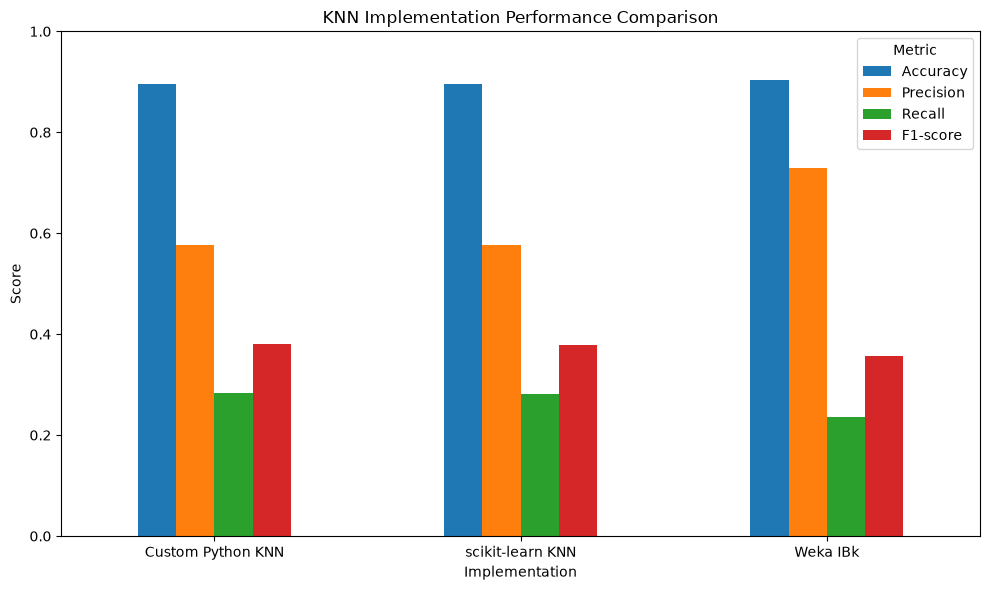

In [54]:
plot_df = comparison_df.set_index("Implementation")[
    ["Accuracy", "Precision", "Recall", "F1-score"]
]

plot_df.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("KNN Implementation Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Implementation")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()